In [1]:
#Importancion de librerias
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
#Crear el dataframe
path= "../data/BostonHousingData.csv"
df=pd.read_csv(path)
display(df.head(10))


,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.00632,18.0,2.31,0.0,0.538,6.575,65.2,4.0900,1,296,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0.0,0.469,6.421,78.9,4.9671,2,242,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0.0,0.469,7.185,61.1,4.9671,2,242,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0.0,0.458,6.998,45.8,6.0622,3,222,18.7,394.63,2.94,33.4
4,0.02985,0.0,2.18,0.0,0.458,6.430,58.7,6.0622,3,222,18.7,394.12,5.21,28.7
5,0.08829,12.5,7.87,NaN,0.524,6.012,66.6,5.5605,5,311,15.2,395.60,12.43,22.9
6,0.14455,12.5,7.87,0.0,0.524,6.172,96.1,5.9505,5,311,15.2,396.90,19.15,27.1
7,0.21124,12.5,7.87,0.0,0.524,5.631,100.0,6.0821,5,311,15.2,386.63,29.93,16.5
8,0.17004,12.5,7.87,NaN,0.524,6.004,85.9,6.5921,5,311,15.2,386.71,17.10,18.9
9,0.22489,12.5,7.87,0.0,0.524,6.377,94.3,6.3467,5,311,15.2,392.52,20.45,15.0


In [4]:
df.corr()

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
CRIM,1.000000,-0.190300,0.392939,-0.052920,0.405560,-0.216965,0.346478,-0.368526,0.619086,0.573908,0.277927,-0.384390,0.444943,-0.388563
ZN,-0.190300,1.000000,-0.535755,-0.051217,-0.519576,0.328074,-0.574214,0.658616,-0.311275,-0.314283,-0.414639,0.175524,-0.414193,0.381569
INDUS,0.392939,-0.535755,1.000000,0.065620,0.761900,-0.388338,0.639695,-0.708680,0.594995,0.726533,0.391879,-0.362877,0.590690,-0.480247
CHAS,-0.052920,-0.051217,0.065620,1.000000,0.083147,0.104596,0.091068,-0.100694,0.006592,-0.026551,-0.107163,0.052596,-0.047424,0.181142
NOX,0.405560,-0.519576,0.761900,0.083147,1.000000,-0.302316,0.728374,-0.769177,0.600079,0.660050,0.184851,-0.383634,0.582641,-0.424773
RM,-0.216965,0.328074,-0.388338,0.104596,-0.302316,1.000000,-0.244178,0.203955,-0.210180,-0.291862,-0.360338,0.127337,-0.614339,0.692123
AGE,0.346478,-0.574214,0.639695,0.091068,0.728374,-0.244178,1.000000,-0.750239,0.448100,0.501646,0.272021,-0.276920,0.602891,-0.389876
DIS,-0.368526,0.658616,-0.708680,-0.100694,-0.769177,0.203955,-0.750239,1.000000,-0.484910,-0.531309,-0.234634,0.295298,-0.493328,0.248831
RAD,0.619086,-0.311275,0.594995,0.006592,0.600079,-0.210180,0.448100,-0.484910,1.000000,0.908200,0.467558,-0.452946,0.479541,-0.383306
TAX,0.573908,-0.314283,0.726533,-0.026551,0.660050,-0.291862,0.501646,-0.531309,0.908200,1.000000,0.461875,-0.449283,0.536110,-0.468589


In [5]:
#Hipotesis: La variable que se nos pide predecir es la Glucosa a partir de una variable explicativa
y = df["MEDV"]
print(y.shape)
display(y.head(10))

(486,)


0    24.0
1    21.6
2    34.7
3    33.4
4    28.7
5    22.9
6    27.1
7    16.5
8    18.9
9    15.0
Name: MEDV, dtype: float64

In [5]:
matrix =df.corr()
display(matrix)

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
fixed acidity,1.000000,-0.256131,0.671703,0.114777,0.093705,-0.153794,-0.113181,0.668047,-0.682978,0.183006,-0.061668,0.124052
volatile acidity,-0.256131,1.000000,-0.552496,0.001918,0.061298,-0.010504,0.076470,0.022026,0.234937,-0.260987,-0.202288,-0.390558
citric acid,0.671703,-0.552496,1.000000,0.143577,0.203823,-0.060978,0.035533,0.364947,-0.541904,0.312770,0.109903,0.226373
residual sugar,0.114777,0.001918,0.143577,1.000000,0.055610,0.187049,0.203028,0.355283,-0.085652,0.005527,0.042075,0.013732
chlorides,0.093705,0.061298,0.203823,0.055610,1.000000,0.005562,0.047400,0.200632,-0.265026,0.371260,-0.221141,-0.128907
free sulfur dioxide,-0.153794,-0.010504,-0.060978,0.187049,0.005562,1.000000,0.667666,-0.021946,0.070377,0.051658,-0.069408,-0.050656
total sulfur dioxide,-0.113181,0.076470,0.035533,0.203028,0.047400,0.667666,1.000000,0.071269,-0.066495,0.042947,-0.205654,-0.185100
density,0.668047,0.022026,0.364947,0.355283,0.200632,-0.021946,0.071269,1.000000,-0.341699,0.148506,-0.496180,-0.174919
pH,-0.682978,0.234937,-0.541904,-0.085652,-0.265026,0.070377,-0.066495,-0.341699,1.000000,-0.196648,0.205633,-0.057731
sulphates,0.183006,-0.260987,0.312770,0.005527,0.371260,0.051658,0.042947,0.148506,-0.196648,1.000000,0.093595,0.251397


In [6]:
#Definir variable explicativa
X = df[["LSTAT"]]
print(X.shape)
display(X.head(10))

(486, 1)


,LSTAT
0,4.98
1,9.14
2,4.03
3,2.94
4,5.21
5,12.43
6,19.15
7,29.93
8,17.10
9,20.45


In [7]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split       
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

In [7]:
X_train, X_test, y_train, y_test =train_test_split(X,y,random_state=42, test_size=0.2)
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(404, 1)
(102, 1)
(404,)
(102,)


In [8]:
y_train.head(10)

477    12.0
15     19.9
332    19.4
423    13.4
19     18.2
325    24.6
335    21.1
56     24.7
437     8.7
409    27.5
Name: MEDV, dtype: float64

In [8]:
model = LinearRegression()
model.fit(X,y)                   #Posible sobreajuste
#model.fit(X_train, y_train)       #Entrenamiento del modelo

LinearRegression()

In [9]:
#Generar predicciones para "evaluar" el modelo
y_pred = model.predict(X)
print(y_pred.shape)
y_pred

(486,)


array([29.77477606, 25.83584206, 30.67429224, 31.7063687 , 29.55699846,
       22.72067551, 16.35778213,  6.15064066, 18.29884336, 15.12686526,
       21.92531384, 19.61497755, 26.6690781 , 24.77535983, 26.47023768,
       28.25980145, 20.59971105, 23.42135127, 23.80956352, 14.58715555,
       21.39507272, 16.76493156, 15.66657496, 19.05633066, 18.85749024,
       20.46715077, 18.12840871, 22.37033763, 23.14676212, 13.09111812,
       22.14309144,  8.25266794, 17.11526944, 15.23101976, 23.68647183,
       26.18617994, 24.89845152, 30.39970309, 32.61535347, 29.90733634,
       28.98888298, 27.44550259, 25.44762982, 24.82270279, 21.0920778 ,
       16.68918283,  5.31740462, 19.15101658, 21.7548792 , 25.56125292,
       29.49071832, 26.50811205, 20.47661936, 29.93574212, 29.02675735,
       30.75004097, 27.99468089, 25.76009333, 22.03893694, 20.81748865,
       28.11777258, 25.49497278, 26.86791852, 30.06830239, 24.79429702,
       26.82057556, 22.09574848, 26.16724276, 28.12724117, 25.13

In [10]:
#Medir la precision del modelo
r2= r2_score(y_pred, y)
mae= mean_absolute_error(y_pred, y)
mse=mean_squared_error(y_pred, y)

print(f"r2: {r2:.4f}, mae: {mae:.4f}, mse: {mse:.4f}")

r2: 0.1531, mae: 4.4962, mse: 38.8023


In [11]:
#Definir ecuacion de regresion lineal
print(model.coef_)            #el valor de m
print(model.intercept_)       #el valor de b

[-0.94685913]
34.490134551493


<Axes: xlabel='MEDV'>

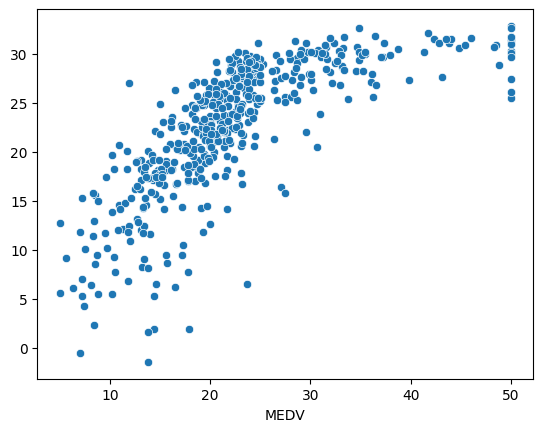

In [19]:
sns.scatterplot(x=y, y=y_pred)

<Axes: xlabel='LSTAT', ylabel='MEDV'>

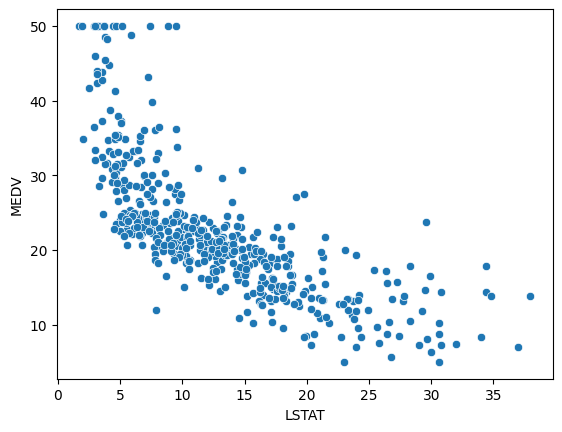

In [17]:
sns.scatterplot(x=df["LSTAT"], y=y)

<Axes: xlabel='LSTAT'>

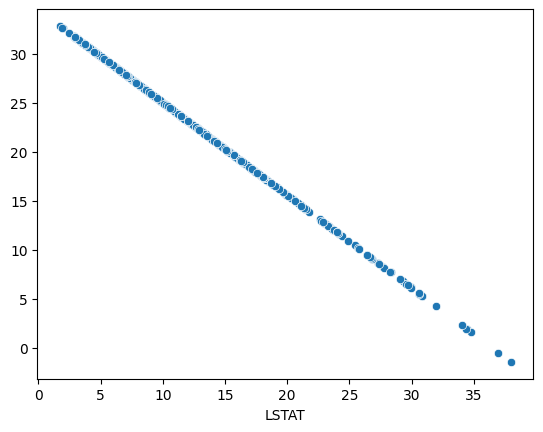

In [18]:
sns.scatterplot(x=df["LSTAT"], y=y_pred)